In [1]:
import pandas as pd
from pathlib import Path

# ============================================================================
# KONFIGURASI PATH KHUSUS JUPYTER NOTEBOOK (.ipynb)
# ============================================================================
CURRENT_DIR = Path.cwd()

# Deteksi root project otomatis
if CURRENT_DIR.name == "praprocessing":
    PROJECT_DIR = CURRENT_DIR.parent
else:
    PROJECT_DIR = CURRENT_DIR

# Folder tempat CSV hasil labeling berada
LABELING_DIR = PROJECT_DIR / "labeling"

# File output akhir disimpan di folder praprocessing
OUTPUT_FILE = PROJECT_DIR / "praprocessing" / "aggregated_labels.csv"

LABELERS = ["shafwa", "hans", "gerald", "clay", "baqhiz"]

def calculate_majority(row):
    """Fungsi untuk menghitung persentase dan menentukan label akhir per baris"""
    counts = {'netral': 0, 'positif': 0, 'negatif': 0}
    total_votes = 0

    # Hitung jumlah tiap label
    for val in row:
        if pd.notna(val) and str(val).strip() != '':
            val_lower = str(val).lower().strip()
            if val_lower in counts:
                counts[val_lower] += 1
                total_votes += 1

    # Jika belum ada yang melabeli sama sekali
    if total_votes == 0:
        return pd.Series({
            'netral': '0%',
            'positif': '0%',
            'negatif': '0%',
            'final_label': 'belum dilabeli'
        })

    # Hitung persentase
    percentages = {k: (v / total_votes) * 100 for k, v in counts.items()}
    
    # Cari nilai persentase tertinggi
    max_perc = max(percentages.values())
    
    # Cari tahu label apa saja yang punya persentase tertinggi (untuk cek seri/tie)
    max_labels = [k for k, v in percentages.items() if v == max_perc]

    # Jika ada lebih dari 1 label yang punya nilai tertinggi (seri) -> gagal diidentifikasi
    if len(max_labels) > 1:
        final_label = 'gagal diidentifikasi'
    else:
        final_label = max_labels[0]

    return pd.Series({
        'netral': f"{percentages['netral']:.0f}%",
        'positif': f"{percentages['positif']:.0f}%",
        'negatif': f"{percentages['negatif']:.0f}%",
        'final_label': final_label
    })

def main():
    print("="*60)
    print("🔄 MENGGABUNGKAN HASIL LABELING (MAJORITY VOTE)")
    print("="*60)

    base_df = None
    labels_df = pd.DataFrame()

    # 1. Load data dari kelima file di dalam folder labeling/
    for name in LABELERS:
        file_path = LABELING_DIR / f"labels_{name}.csv"
        
        if file_path.exists():
            print(f"✔️ Membaca file {file_path.relative_to(PROJECT_DIR)}...")
            df = pd.read_csv(file_path, dtype=str)
            df['label'] = df['label'].fillna('')
            
            # Ambil struktur data dasarnya dari file pertama yang ketemu
            if base_df is None:
                base_df = df.drop(columns=['label'])
                
            # Kumpulkan kolom label tiap orang
            labels_df[name] = df['label']
        else:
            print(f"⚠️ Warning: File {file_path.name} tidak ditemukan/belum ada di folder labeling/.")

    if base_df is None:
        print("❌ Gagal: Tidak ada file CSV labeler yang ditemukan di folder labeling/!")
        return

    print("\n⏳ Menghitung suara terbanyak dan persentase...")
    
    # 2. Proses majority vote per baris
    results_df = labels_df.apply(calculate_majority, axis=1)

    # 3. Gabungkan data dasar dengan hasil voting
    final_df = pd.concat([base_df, results_df], axis=1)

    # 4. Susun urutan kolom sesuai request
    desired_columns = ['post_url', 'username', 'comment_text', 'timestamp', 'likes_count', 
                       'netral', 'positif', 'negatif', 'final_label']
    
    final_columns = [col for col in desired_columns if col in final_df.columns]
    
    for col in final_df.columns:
        if col not in final_columns:
            final_columns.append(col)

    final_df = final_df[final_columns]

    # 5. Pastikan folder tujuan ada, lalu simpan
    OUTPUT_FILE.parent.mkdir(parents=True, exist_ok=True)
    final_df.to_csv(OUTPUT_FILE, index=False, encoding='utf-8')
    
    print(f"\n✅ Selesai! Hasil voting berhasil disimpan di:")
    # Menampilkan path dengan aman
    try:
        print(f"👉 {OUTPUT_FILE.relative_to(PROJECT_DIR)}")
    except ValueError:
        print(f"👉 {OUTPUT_FILE}")

# Jalankan fungsinya
main()

🔄 MENGGABUNGKAN HASIL LABELING (MAJORITY VOTE)
✔️ Membaca file labeling\labels_shafwa.csv...
✔️ Membaca file labeling\labels_hans.csv...
✔️ Membaca file labeling\labels_gerald.csv...
✔️ Membaca file labeling\labels_clay.csv...
✔️ Membaca file labeling\labels_baqhiz.csv...

⏳ Menghitung suara terbanyak dan persentase...

✅ Selesai! Hasil voting berhasil disimpan di:
👉 praprocessing\aggregated_labels.csv


In [2]:
import pandas as pd
import re
import emoji
from pathlib import Path

# ============================================================================
# KONFIGURASI PATH KHUSUS JUPYTER NOTEBOOK (.ipynb)
# ============================================================================
CURRENT_DIR = Path.cwd()

# Deteksi root project otomatis (PBAAnalysisSentiment)
if CURRENT_DIR.name == "praprocessing":
    PROJECT_DIR = CURRENT_DIR.parent
else:
    PROJECT_DIR = CURRENT_DIR

# File input (file hasil agregasi yang sudah di-rename)
INPUT_FILE = PROJECT_DIR / "praprocessing" / "aggregated_labels.csv"

# File output setelah dibersihkan
OUTPUT_FILE = PROJECT_DIR / "praprocessing" / "cleaned_aggregated_labels.csv"

def main():
    print("="*60)
    print("🧹 PEMBERSIHAN TEKS (EMOJI, SPASI, NULL)")
    print("="*60)

    # 1. Cek apakah file input ada
    if not INPUT_FILE.exists():
        print(f"❌ Error: File {INPUT_FILE.name} tidak ditemukan di folder praprocessing!")
        return

    try:
        print(f"✔️ Membaca file: {INPUT_FILE.relative_to(PROJECT_DIR)}")
    except ValueError:
        print(f"✔️ Membaca file: {INPUT_FILE}")
        
    # 2. Load data
    df = pd.read_csv(INPUT_FILE, dtype=str)
    
    # Cek apakah kolom comment_text ada
    if 'comment_text' not in df.columns:
        print("❌ Error: Kolom 'comment_text' tidak ditemukan dalam dataset!")
        return

    total_awal = len(df)
    print(f"📊 Jumlah data awal: {total_awal} baris.")

    # 3. PROSES PEMBERSIHAN
    print("\n⏳ Sedang membersihkan kolom 'comment_text'...")
    
    # a. Hapus Emoji (Pastikan data diproses sebagai string)
    df['comment_text'] = df['comment_text'].apply(
        lambda x: emoji.replace_emoji(str(x), replace='') if pd.notna(x) else x
    )
    
    # b. Hapus spasi berlebih (awal, akhir, dan ganda di tengah)
    df['comment_text'] = df['comment_text'].str.strip()
    df['comment_text'] = df['comment_text'].replace(r'\s+', ' ', regex=True)
    
    # c. Ubah teks kosong, 'nan', atau 'None' menjadi format Null bawaan pandas (NA)
    df['comment_text'] = df['comment_text'].replace({
        '': pd.NA, 
        'nan': pd.NA, 
        'NaN': pd.NA, 
        'None': pd.NA
    })
    
    # d. Hapus baris yang comment_text-nya kosong/Null
    df = df.dropna(subset=['comment_text']).reset_index(drop=True)

    total_akhir = len(df)
    baris_dihapus = total_awal - total_akhir
    
    print(f"✔️ Pembersihan selesai!")
    print(f"📉 Baris yang dihapus (karena kosong atau hanya berisi emoji): {baris_dihapus} baris.")
    print(f"📈 Sisa data valid: {total_akhir} baris.")

    # 4. Simpan ke CSV baru
    OUTPUT_FILE.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(OUTPUT_FILE, index=False, encoding='utf-8')
    
    print(f"\n✅ Data bersih berhasil disimpan di:")
    try:
        print(f"👉 {OUTPUT_FILE.relative_to(PROJECT_DIR)}")
    except ValueError:
        print(f"👉 {OUTPUT_FILE}")

# Jalankan fungsinya
main()

🧹 PEMBERSIHAN TEKS (EMOJI, SPASI, NULL)
✔️ Membaca file: praprocessing\aggregated_labels.csv
📊 Jumlah data awal: 2201 baris.

⏳ Sedang membersihkan kolom 'comment_text'...
✔️ Pembersihan selesai!
📉 Baris yang dihapus (karena kosong atau hanya berisi emoji): 95 baris.
📈 Sisa data valid: 2106 baris.

✅ Data bersih berhasil disimpan di:
👉 praprocessing\cleaned_aggregated_labels.csv


📊 MENGHITUNG DAN VISUALISASI HASIL LABELING

📈 RINGKASAN DATA:
Total Komentar        : 2106
------------------------------
🟢 Positif            : 434
⚪ Netral             : 125
🔴 Negatif            : 1501
🟡 Tidak Terdefinisi  : 46 (Gagal/Seri: 46, Belum: 0)
------------------------------

✅ Visualisasi berhasil disimpan di folder: praprocessing/grafik_sentimen.png


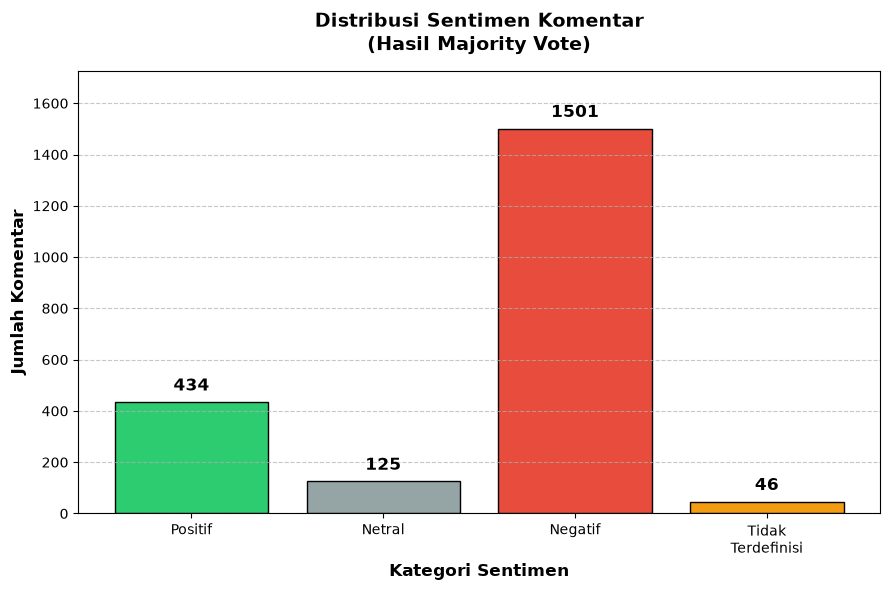

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================================
# KONFIGURASI PATH (KHUSUS JUPYTER NOTEBOOK)
# ============================================================================
# Ambil lokasi folder tempat notebook ini dijalankan
CURRENT_DIR = Path.cwd()

# Cek apakah notebook berada di dalam folder 'praprocessing' atau di luar (root)
if CURRENT_DIR.name == "praprocessing":
    PROJECT_DIR = CURRENT_DIR.parent
else:
    PROJECT_DIR = CURRENT_DIR

DATA_FILE = PROJECT_DIR / "praprocessing" / "cleaned_aggregated_labels.csv"
OUTPUT_IMAGE = PROJECT_DIR / "praprocessing" / "grafik_sentimen.png"

def main():
    print("="*60)
    print("📊 MENGHITUNG DAN VISUALISASI HASIL LABELING")
    print("="*60)

    # 1. Cek apakah file data ada
    if not DATA_FILE.exists():
        print(f"❌ Error: File tidak ditemukan di path: {DATA_FILE}")
        print("Pastikan kamu sudah menjalankan proses agregasi terlebih dahulu.")
        return

    # 2. Baca Data
    df = pd.read_csv(DATA_FILE)
    
    if 'final_label' not in df.columns:
        print("❌ Error: Kolom 'final_label' tidak ditemukan di dalam dataset.")
        return

    # 3. Hitung jumlah masing-masing label
    counts = df['final_label'].value_counts()

    # Ambil nilai masing-masing (gunakan .get() agar tidak error jika nilainya 0)
    positif = counts.get('positif', 0)
    negatif = counts.get('negatif', 0)
    netral = counts.get('netral', 0)
    
    # Gabungkan 'gagal diidentifikasi' (seri) dan 'belum dilabeli' sebagai "Tidak Terdefinisi"
    gagal = counts.get('gagal diidentifikasi', 0)
    belum = counts.get('belum dilabeli', 0)
    tidak_terdefinisi = gagal + belum
    
    total_data = len(df)

    # 4. Tampilkan informasi di output cell
    print("\n📈 RINGKASAN DATA:")
    print(f"Total Komentar        : {total_data}")
    print("-" * 30)
    print(f"🟢 Positif            : {positif}")
    print(f"⚪ Netral             : {netral}")
    print(f"🔴 Negatif            : {negatif}")
    print(f"🟡 Tidak Terdefinisi  : {tidak_terdefinisi} (Gagal/Seri: {gagal}, Belum: {belum})")
    print("-" * 30)

    # 5. Membuat Visualisasi Bar Chart
    labels = ['Positif', 'Netral', 'Negatif', 'Tidak\nTerdefinisi']
    values = [positif, netral, negatif, tidak_terdefinisi]
    
    # Warna untuk masing-masing bar
    colors = ['#2ecc71', '#95a5a6', '#e74c3c', '#f39c12']

    plt.figure(figsize=(9, 6))
    bars = plt.bar(labels, values, color=colors, edgecolor='black', linewidth=1)

    # Menambahkan angka di atas masing-masing bar chart
    for bar in bars:
        yval = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2, 
            yval + (max(values) * 0.02), # Jarak teks sedikit di atas bar
            int(yval), 
            ha='center', va='bottom', fontweight='bold', fontsize=12
        )

    # Mempercantik grafik
    plt.title('Distribusi Sentimen Komentar\n(Hasil Majority Vote)', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Kategori Sentimen', fontsize=12, fontweight='bold')
    plt.ylabel('Jumlah Komentar', fontsize=12, fontweight='bold')
    
    # Menghindari error jika semua value 0
    max_val = max(values) if max(values) > 0 else 10
    plt.ylim(0, max_val * 1.15) 
    
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    # Simpan dan Tampilkan
    plt.tight_layout()
    plt.savefig(OUTPUT_IMAGE, dpi=300) 
    
    print(f"\n✅ Visualisasi berhasil disimpan di folder: {OUTPUT_IMAGE.parent.name}/{OUTPUT_IMAGE.name}")
    
    # Memunculkan grafik di dalam output Jupyter Notebook
    plt.show()

# Panggil fungsi main()
main()

In [4]:
!pip install pandas numpy statsmodels matplotlib emoji

  Using cached statsmodels-0.15.0-cp313-cp313-win_amd64.whl.metadata (9.6 kB)
  Using cached patsy-1.0.3-py2.py3-none-any.whl.metadata (3.7 kB)
  Using cached formulaic-1.2.2-py3-none-any.whl.metadata (7.0 kB)
  Using cached interface_meta-2.0.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached narwhals-2.26.0-py3-none-any.whl.metadata (15 kB)
  Using cached wrapt-2.5.0-cp313-cp313-win_amd64.whl.metadata (7.7 kB)
Using cached statsmodels-0.15.0-cp313-cp313-win_amd64.whl (11.3 MB)

   ---------------------------------------- 0/6 [wrapt]
   ------ --------------------------------- 1/6 [patsy]
   ------ --------------------------------- 1/6 [patsy]
   ------------- -------------------------- 2/6 [narwhals]
   ------------- -------------------------- 2/6 [narwhals]
   ------------- -------------------------- 2/6 [narwhals]
   ------------- -------------------------- 2/6 [narwhals]
   ------------- -------------------------- 2/6 [narwhals]
   ------------- -------------------------- 2/6 [na


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
